# Prelim

## Imports, Basic Data Check

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from typing import Optional, Union
import time
from tqdm.notebook import tqdm 
import networkx as nx
from pyvis.network import Network

In [2]:
col_names = ["flow", "agent_ip", "src_port_data_link_router", "dst_port_data_link_router", "src_mac", "dst_mac", "ethernet_type", "dst_vlan", "src_vlan", "src_ip", "dst_ip", "tcp6_udp17", "ip_type_of_service", "ip_time_to_live", "src_port", "dst_port", "tcp_flags", "packet_size", "ip_size", "sampling_rate"]
df_data_2 = pd.read_csv("./Data/Data_2.csv", names = col_names)
col_names_df_test = col_names
col_names_df_test.insert(1, "UNK")
df_test_SFlow = pd.read_csv("./Data/test_SFLow_data.csv", names = col_names_df_test, dtype= str)

In [3]:
display(df_data_2.head())
display(df_test_SFlow.head())
print("df data shape", df_data_2.shape)
print("df test shape", df_test_SFlow.shape)

,flow,agent_ip,src_port_data_link_router,dst_port_data_link_router,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,src_ip,dst_ip,tcp6_udp17,ip_type_of_service,ip_time_to_live,src_port,dst_port,tcp_flags,packet_size,ip_size,sampling_rate
0,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919.0,919,74.125.10.59,137.132.38.238,17,0x00,63,443.0,62758,0x00,1396,1378,2048
1,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919.0,919,173.194.22.215,137.132.228.29,6,0x00,63,443.0,39740,0x10,1438,1420,2048
2,FLOW,203.30.38.251,199,131,544b8cf9a7df,001cb0c88e40,0x0800,600.0,43,193.62.193.9,202.130.56.153,6,0x00,246,80.0,35794,0x18,272,250,2048
3,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919.0,43,74.125.130.132,192.122.131.33,6,0x00,52,443.0,5287,0x10,1418,1400,2048
4,FLOW,203.30.38.251,129,193,00135f21bc80,0031466b23cf,0x0800,11.0,919,155.69.160.69,74.125.68.139,17,0x60,59,48361.0,443,0x00,89,67,2048


,flow,UNK,agent_ip,src_port_data_link_router,dst_port_data_link_router,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,...,dst_ip,tcp6_udp17,ip_type_of_service,ip_time_to_live,src_port,dst_port,tcp_flags,packet_size,ip_size,sampling_rate
0,FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,...,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
1,FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,...,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
2,FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,...,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
3,FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,...,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
4,FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,...,50,0x00,245,0,0,0x00,1518,1496,2048,NaN


df data shape (177232, 20)
df test shape (1200, 21)


## Utils

### Ports

In [4]:
# at first i got the wrong port as application port so looked up a lot of ports
PORT_APP_MAP = {
    1: "OBSCURE: TCP Port Service Multiplexer",
    2: "OBSCURE: Compressnet's management utility, a obsolete protocol",
    3: "compressnet", # OBSCURE, a obsolete protocol
    6: "NOT FOUND",
    11: "OBSCURE: Active Users",
    12: "OBSCURE: Dark Ages of Camelot (game) / NOT FOUND",
    14: "NOT FOUND",
    18: "OBSCURE: Message Send Protocol",
    19: "OBSCURE: Character Generator",
    20: "ftp", #FTP data
    21: "FTP-Control",
    22: "SSH",
    23: "OBSCURE: Telnet",
    25: "SMTP",
    53: "DNS",
    67: "DHCP-Server",
    68: "DHCP-Client",
    80: "HTTP",
    110: "POP3",
    123: "NTP",
    129: "OBSCURE: Password Generator Protocol",
    130: "cisco-fna", # OBSCURE
    131: "OBSCURE: cisco network control/management traffic",
    133: "OBSCURE: Farnaz Statistics Service",
    134: "OBSCURE: INGRES-NET Service",
    135: "OBSCURE: Remote Procedure Call",
    136: "OBSCURE: PROFILE Naming System",
    138: "OBSCURE: NETBIOS Name Service",
    143: "IMAP",
    161: "SNMP",
    193: "srmp", # OBSCURE
    195: "OBSCURE: DNSIX Network Level Module Audit",
    199: "smux", # OBSCURE, https://www.speedguide.net/port.php?port=199 say also by CISCO
    200: "OBSCURE: IBM System Resource Controller",
    256: "OBSCURE: RAP (TCP/UDP)",
    443: "HTTPS",
    445: "SMB",
    3306: "MySQL",
    5432: "PostgreSQL",
    6379: "Redis",
    8080: "HTTP-Alt",
    1073741823: "OBSCURE: VPN or similar"
}


### Graphing

In [5]:
def draw_1_var_bar_chart(
    field_name,
    df,
    top_n: int = 5,
    ax=None,
    rot=45,
    aggregated: bool = False,
    count_col: Optional[str] = None,
    color: str = "tab:blue",
    title: Optional[str] = None,
    total_entries: Optional[int] = None
):
    """
    Draw a top-N bar chart for a single column in df, with counts and percentage labels.

    Parameters:
        field_name (str): Column name to plot.
        df (pd.DataFrame): The DataFrame containing the data.
        top_n (int): Number of top categories to display.
        ax (matplotlib.axes.Axes): Optional, axes to plot on.
        rot (int): Rotation of x-axis tick labels.
        aggregated (bool): 
            - False: compute value counts on `field_name`. 
            - True: assume `df` already contains counts in `count_col`.
        count_col (str): Name of the column that contains counts if `aggregated=True`.
        color (str): Color of the bars.
        title (str): Custom title for the chart. If None, defaults to "Top {top_n} {field_name}".
    """
    if field_name not in df.columns:
        raise ValueError(f"{field_name} is not in df columns")
    
    # Handle aggregated vs non-aggregated
    if aggregated:
        if count_col is None or count_col not in df.columns:
            raise ValueError("When aggregated=True, a valid count_col must be provided")
        freq_df = df[[field_name, count_col]].copy()
        freq_df.columns = [field_name, "frequency"]
    else:
        freq_df = df[field_name].value_counts().reset_index()
        freq_df.columns = [field_name, "frequency"]
    
    total = total_entries if total_entries else freq_df["frequency"].sum()
    
    # Create axes if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    
    bar = freq_df.head(top_n).plot(
        kind="bar",
        x=field_name,
        y="frequency",
        legend=False,
        ax=ax,
        color=color
    )
    
    ax.set_title(title if title else f"Top {top_n} {field_name}")
    ax.set_xlabel(field_name)
    ax.set_ylabel(count_col if count_col else "frequency")
    ax.tick_params(axis="x", rotation=rot)
    ax.margins(y=0.3)
    
    labels = [
        f"{count}\n{count / total * 100:.1f}%"
        for count in freq_df.head(top_n)["frequency"]
    ]
    ax.bar_label(bar.containers[0], labels=labels, label_type="edge", padding=3, fontsize=9)
    
    return ax


### IP & organisations

In [6]:
def get_ip_details(
    ip: Union[str, pd.Series],
    get_organisation: bool = False,
    delay: float = 1.0,
    max_retries: int = 3
) -> Union[Optional[str], pd.Series]:
    """
    Fetch IP details from ipinfo.io.
    
    Args:
        ip: A single IP (str) or a pandas Series of IPs.
        get_organisation: If True, returns 'org' field only.
        delay: Delay (seconds) between requests to avoid rate limits.
        max_retries: Number of retries on request failure.
    """
    
    def fetch_ip(addr: str) -> Optional[dict]:
        """Fetch details for one IP with retries and delay."""
        for attempt in range(max_retries):
            try:
                response = requests.get(f"https://ipinfo.io/{addr}/json", timeout=5)
                if response.status_code == 429:  # rate limit hit
                    time.sleep(delay)
                    continue
                response.raise_for_status()
                return response.json()
            except requests.RequestException:
                time.sleep(delay)
        print(f"Rate Limit Reached! Max Retries ({delay}) Reached!")
        return None  # if all retries fail

    # --- Case 1: Single IP ---
    if isinstance(ip, str):
        data = fetch_ip(ip)
        if not data:
            return None
        df = pd.DataFrame([data])
        if get_organisation:
            return df.get("org", pd.Series([None])).iloc[0]
        else:
            display(df)
            return None

    # --- Case 2: Series of IPs ---
    elif isinstance(ip, pd.Series):
        results = []

        for addr in tqdm(ip, desc="Fetching IP info", leave=False):
            data = fetch_ip(addr)
            if data:
                df = pd.DataFrame([data])
                if get_organisation:
                    org_value = df.get("org", pd.Series([None])).iloc[0]
                    results.append(org_value)
                else:
                    display(df)
                    results.append(None)
            else:
                results.append(None)
            time.sleep(delay)

        return pd.Series(results, index=ip.index)

    else:
        raise TypeError("ip must be either a string or a pandas Series")

# Exercise 4A: Top Talkers and Listeners

In [7]:
top5_src = df_data_2["src_ip"].value_counts().head(5).reset_index()
top5_dst = df_data_2["dst_ip"].value_counts().head(5).reset_index()

print("Top 5 Talkers")
top5_src["org"] = get_ip_details(top5_src["src_ip"], get_organisation=True)
top5_src.index += 1
display(top5_src)

print("Top 5 Listeners")
top5_dst["org"] = get_ip_details(top5_dst["dst_ip"], get_organisation=True)
top5_dst.index += 1
display(top5_dst)

Top 5 Talkers


Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

,src_ip,count,org
1,13.107.4.50,5960,AS8068 Microsoft Corporation
2,130.14.250.7,4034,AS70 National Library of Medicine
3,155.69.160.38,3866,AS9419 Nanyang Technological University
4,171.67.77.19,2656,AS32 Stanford University
5,155.69.199.255,2587,AS9419 Nanyang Technological University


Top 5 Listeners


Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

,dst_ip,count,org
1,137.132.228.33,5908,AS7472 NUS Information Technology
2,192.122.131.36,4662,AS23767 A-STAR
3,202.51.247.133,4288,AS7610 NUS Gigapop
4,137.132.228.29,4022,AS7472 NUS Information Technology
5,103.37.198.100,3741,AS23767 A-STAR


### Extra: Graphs of frequency

<Axes: title={'center': 'Top 5 Listeners'}, xlabel='org', ylabel='count'>

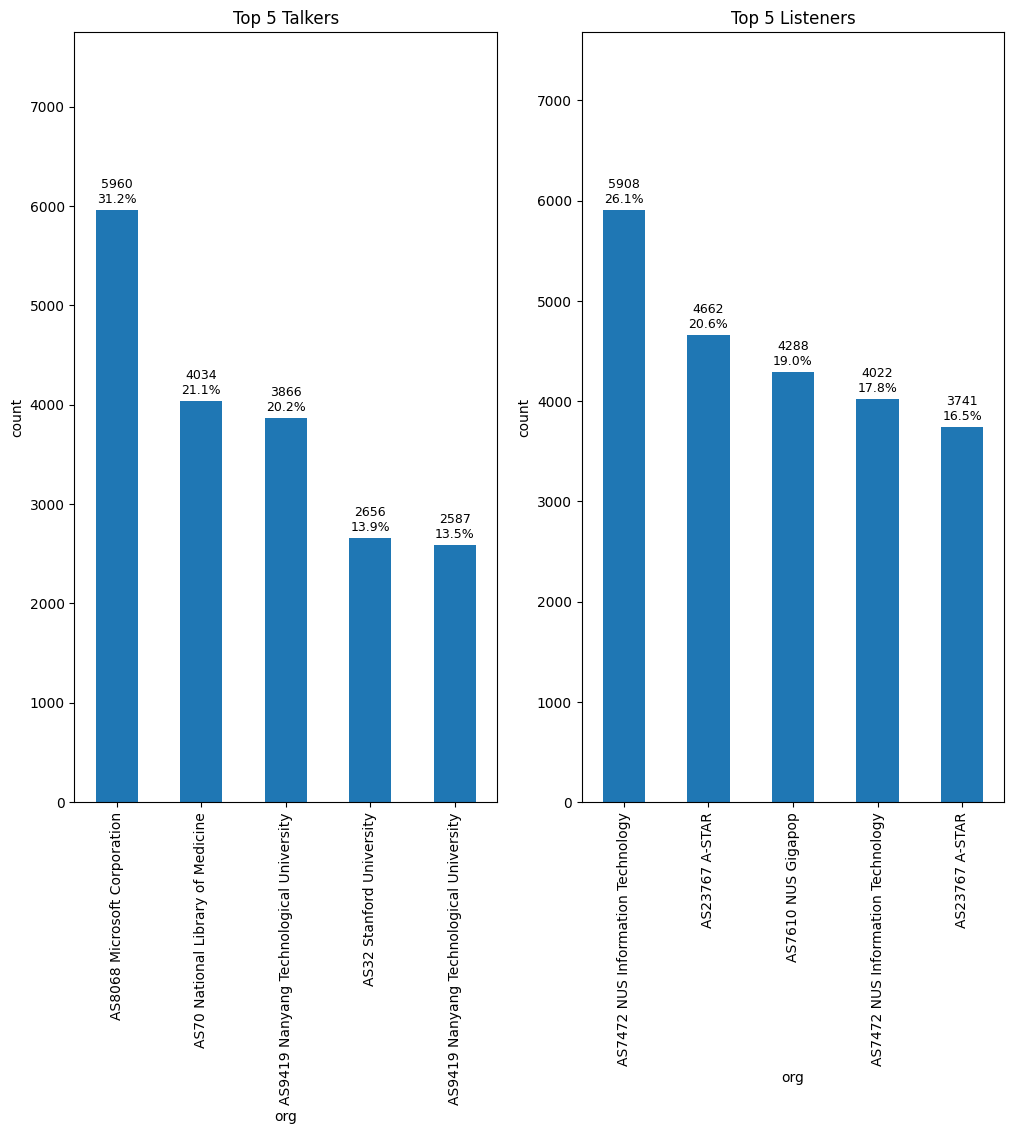

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 10)) 

draw_1_var_bar_chart("org", top5_src, aggregated= True, ax = axes[0], count_col= "count", title = "Top 5 Talkers", rot = 90)
draw_1_var_bar_chart("org", top5_dst, aggregated= True, ax = axes[1], count_col= "count", title = "Top 5 Listeners", rot = 90)

------------------------------------

# Exercise 4B: Transport Protocol

In [9]:
top_protocol = df_data_2["tcp6_udp17"].value_counts().reset_index()
top_protocol["tcp6_udp17"].name = "Header value"
top_protocol["Transport layer protocol"] = top_protocol["tcp6_udp17"].map({
    "0": "HOPOPT",
    "1": "ICMP",
    "2": "IGMP",
    "6": "TCP",
    "17": "UDP",
    "41": "IPv6",
    "47": "GRE",
    "50": "ESP",
    "58": "IPv6-ICMP",
    0: "HOPOPT",
    1: "ICMP",
    2: "IGMP",
    6: "TCP",
    17: "UDP",
    41: "IPv6",
    47: "GRE",
    50: "ESP",
    58: "IPv6-ICMP"
}).fillna("other")

# Reorder columns so 'count' comes last
cols = [col for col in top_protocol.columns if col != "count"] + ["count"]
top_protocol = top_protocol[cols]
top_protocol.index += 1

display(top_protocol)

,tcp6_udp17,Transport layer protocol,count
1,6,TCP,137707
2,17,UDP,36852
3,0,HOPOPT,1216
4,50,ESP,718
5,47,GRE,664
6,1,ICMP,60
7,58,IPv6-ICMP,10
8,41,IPv6,3
9,2,IGMP,2


### Extra: Graphs of frequency

<Axes: title={'center': 'Application by Frequency'}, xlabel='Transport layer protocol', ylabel='count'>

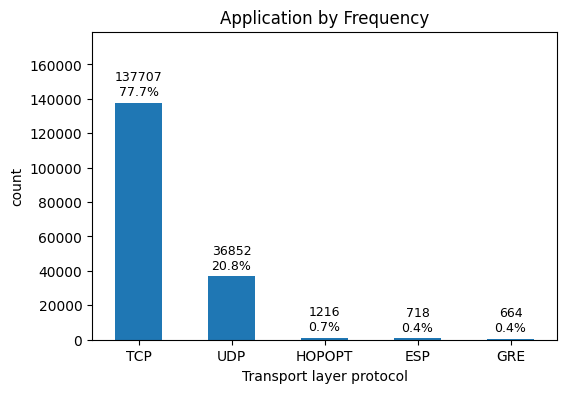

In [10]:
draw_1_var_bar_chart("Transport layer protocol", top_protocol, aggregated= True, count_col= "count", title = "Application by Frequency", rot = 0)

# 4C: Applications Protocol

In [11]:
port_number_df = df_data_2["dst_port"].value_counts().reset_index()
port_number_df.index += 1
port_number_df["service"] = pd.to_numeric(port_number_df["dst_port"], errors="raise").map(PORT_APP_MAP).fillna("Ephemeral Port")
display(port_number_df.head())

,dst_port,count,service
1,443,43208,HTTPS
2,80,11018,HTTP
3,50930,2450,Ephemeral Port
4,15000,2103,Ephemeral Port
5,8160,1354,Ephemeral Port


### Extra: Graphing Dst Port

<Axes: title={'center': 'Top 5 applications'}, xlabel='service', ylabel='count'>

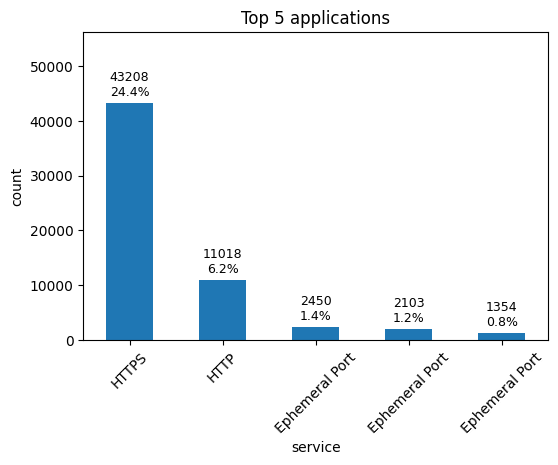

In [12]:
draw_1_var_bar_chart("service", df=port_number_df, title = "Top 5 applications", aggregated= True, count_col= "count")

### Extra: Source Ports

<Axes: title={'center': 'Top 5 applications'}, xlabel='service', ylabel='count'>

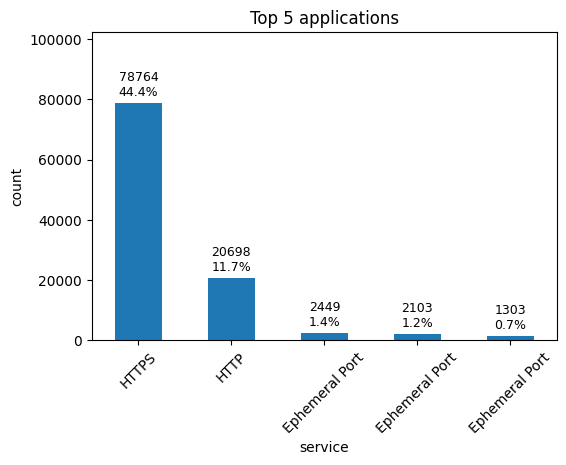

In [13]:
port_number_df = df_data_2["src_port"].value_counts().reset_index()
port_number_df.index += 1
port_number_df["service"] = pd.to_numeric(port_number_df["src_port"], errors="raise").map(PORT_APP_MAP).fillna("Ephemeral Port")
draw_1_var_bar_chart("service", df=port_number_df, title = "Top 5 applications", aggregated= True, count_col= "count")

### Extra: Mystery of the Missing IP

In [14]:
# Investigating funny src_ip = "-" and dst_ip = "-"

no_ip_df = df_data_2[
    (df_data_2["src_ip"] == "-") &
    (df_data_2["dst_ip"] == "-")
]
display(no_ip_df)
# well i guess its just that one singular transmission??

,flow,agent_ip,src_port_data_link_router,dst_port_data_link_router,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,src_ip,dst_ip,tcp6_udp17,ip_type_of_service,ip_time_to_live,src_port,dst_port,tcp_flags,packet_size,ip_size,sampling_rate
87376,FLOW,203.30.38.251,129,1073741823,64f69dd64b9e,01000ccccccd,0x0000,1800.0,1800,-,-,0,0x00,0,0.0,0,0x00,72,64,2048


To the src_ip = "-" and dst_ip = "-" mystery:

GPT says:

Header truncation (most common)
sFlow samples only the first N bytes of the packet. If N is too small and the capture truncated before the IPv4/IPv6 header (for example because of VLAN/MPLS tags or large L2 header), the collector will show L2 fields (MACs) but no IPs.

Non-IP / L2-only traffic
The sampled packet could be a purely Layer-2 frame (e.g., certain control frames, some tunneled L2 traffic) so there is no IP header to parse.

Encapsulation / tunneling (VXLAN, GRE, IP-in-IP, MPLS)
The visible header may be an outer header the collector doesn’t parse to reach the inner IP header. If the inner packet carried the IPs, but the exporter didn’t decapsulate (or the sample truncated before the inner header), the collector will show no IPs.

Malformed or corrupted sample
The sampled bytes might be corrupted or mis-aligned so the parser fails to locate IP header fields.

Exporter/parser bug or mismatched format
The device exporting sFlow may send fields in a way your collector/parser doesn’t expect (different sFlow version, vendor-specific layout), so the collector can extract MACs but not IPs.

Privacy/anonymization or deliberate redaction
Some exporters can be configured to omit IP addresses for privacy — you’d still see agent and L2 fields.

NAT / offload / hardware acceleration
In some hardware offload scenarios the flow recorder sees frames with non-standard fields (or only flow metadata) and not full IP headers.

Value parsing weirdness
Odd field values (e.g. ethernet_type = 0x0000 or dst port = 1073741823) suggest parsing/mapping problems — the collector may be misinterpreting bytes as ports/ethertype.

# Exercise 4D: Traffic

In [26]:
df_traffic = df_data_2.copy()
df_traffic["ip_size"] = pd.to_numeric(df_traffic["ip_size"], errors="raise")
df_traffic["sampling_rate"] = pd.to_numeric(df_traffic["sampling_rate"], errors="raise")
df_traffic["total_bytes"] = df_traffic["ip_size"] * df_traffic["sampling_rate"]
# df_traffic["total_bytes"] = df_traffic["ip_size"] * 2048

total_bytes = df_traffic["total_bytes"].sum()

print(f"Estimated total traffic (bytes): {total_bytes}")
print(f"In MB: {total_bytes / (1024**2):.2f} MiB")
print(f"In GB: {total_bytes / (1024**3):.2f} GiB")

Estimated total traffic (bytes): 348026368000
In MB: 331903.81 MiB
In GB: 324.12 GiB


# Exercise 4E: Additional Analysis

## 4E1: Top Pairs

In [16]:
# filter here so later the label generation easier
df_traffic = df_traffic[
    (df_traffic["src_ip"].notna()) &
    (df_traffic["dst_ip"].notna()) &
    (df_traffic["src_ip"] != "-") &
    (df_traffic["dst_ip"] != "-")
]
# Here reset index doesnt sort the list since it strips the groups rather than usual strip index of series
top_pairs = df_traffic.groupby(["src_ip", "dst_ip"])["total_bytes"].sum().reset_index()
# so here sort manually
top_pairs.sort_values("total_bytes", ascending=False, inplace=True)
top_pairs = top_pairs[:5]

Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

<Axes: title={'center': 'Top 5 pairs'}, xlabel='pair', ylabel='total_bytes'>

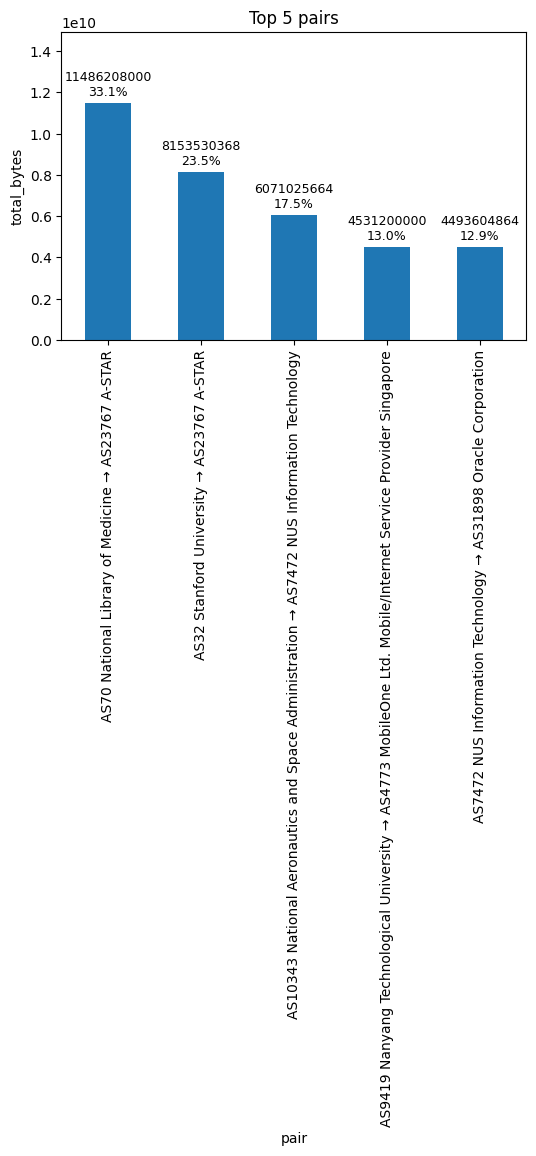

In [17]:
top_pairs["pair"] = get_ip_details(top_pairs["src_ip"], get_organisation=True) + " → " + get_ip_details(top_pairs["dst_ip"], get_organisation=True) # type: ignore
draw_1_var_bar_chart("pair", top_pairs, count_col="total_bytes", aggregated=True, title = "Top 5 pairs", rot=90)

## 4E2: Visualising the communication between different IP Hosts

In [18]:
# Step 1: Filter valid src/dst IPs
df_filtered = df_data_2[
    (df_data_2["src_ip"].notna()) &
    (df_data_2["dst_ip"].notna()) &
    (df_data_2["src_ip"] != "-") &
    (df_data_2["dst_ip"] != "-")
]

# Step 2: Group by pairs and sum sampling rate
pair_weights = df_filtered.groupby(
    ["src_ip", "dst_ip"]
)["sampling_rate"].sum().reset_index(name="weight")

# Step 3: Take the top 20 heaviest edges
top_pairs = pair_weights.nlargest(20, "weight")

# Compute total traffic for percentage
total_traffic = pair_weights["weight"].sum()

# Step 4: Build NetworkX graph
G = nx.DiGraph()
for _, row in top_pairs.iterrows():
    G.add_edge(row["src_ip"], row["dst_ip"], weight=row["weight"])

# Step 5: Compute node total traffic (in + out)
node_weights = {}
for u, v, data in G.edges(data=True):
    w = data["weight"]
    node_weights[u] = node_weights.get(u, 0) + w
    node_weights[v] = node_weights.get(v, 0) + w

# Step 6: Create PyVis network
net = Network(height="800px", width="100%", directed=True, notebook=True)
net.toggle_physics(True)

# Add nodes with proportional size
for node in G.nodes():
    weight = node_weights.get(node, 1)
    size = (weight / max(node_weights.values())) * 50 + 10  # scale sizes
    net.add_node(node, label=node, title=f"Total traffic: {weight}", value=size)

# Add edges with tooltip showing weight and %
for u, v, data in G.edges(data=True):
    weight = data["weight"]
    percent = (weight / total_traffic) * 100
    edge_label = f"{weight} packets ({percent:.2f}%)"
    net.add_edge(
        u, v,
        value=weight,
        title=edge_label,   # Shows on hover
        label=""            # No cluttered inline edge text
    )

# ✅ Export & show
net.show("top20_ip_network.html")
print("✅ Graph saved as 'top20_ip_network.html'. Open it in your browser.")


top20_ip_network.html
✅ Graph saved as 'top20_ip_network.html'. Open it in your browser.


### Extra

In [19]:
# quite a lot of obscure ones here
display(port_number_df)

,src_port,count,service
1,443.0,78764,HTTPS
2,80.0,20698,HTTP
3,50138.0,2449,Ephemeral Port
4,48975.0,2103,Ephemeral Port
5,50148.0,1303,Ephemeral Port
...,...,...,...
19894,40441.0,1,Ephemeral Port
19895,11482.0,1,Ephemeral Port
19896,34576.0,1,Ephemeral Port
19897,26266.0,1,Ephemeral Port


In [20]:
def aggregate(fields:list[str], df:pd.DataFrame, display_df:bool = True, display_other_rows = False) -> pd.DataFrame:
    columns = fields + ["count", "proportion"]
    if len(fields) == 0:
        raise Exception("fields must be nonempty")
    elif len(fields) == 1:
        aggregated_df = df[fields[0]].value_counts().reset_index()
        total = aggregated_df["count"].sum(axis = 0)
        aggregated_df["proportion"] = aggregated_df["count"] / total
        if display_df:
            print(f"Aggregating by {fields[0]}")
            if display_other_rows:
                display(aggregated_df)
            else: 
                display(aggregated_df[columns])
        return aggregated_df
    else:
        aggregated_df = df.groupby(fields).size().reset_index(name="count")
        aggregated_df = aggregated_df.sort_values(by="count", ascending=False)
        
        total = aggregated_df["count"].sum(axis = 0)
        aggregated_df["proportion"] = aggregated_df["count"] / total
        if display_df:
            print(f"Aggregating by {fields[0]}")
            if display_other_rows:
                display(aggregated_df)
            else: 
                display(aggregated_df[columns])
        return aggregated_df

In [23]:
col_names = ["flow", "agent_ip", "src_port_data_link_router", "dst_port_data_link_router", "src_mac", "dst_mac", "ethernet_type", "dst_vlan", "src_vlan", "src_ip", "dst_ip", "tcp6_udp17", "ip_type_of_service", "ip_time_to_live", "src_port", "dst_port", "tcp_flags", "packet_size", "ip_size", "sampling_rate"]

# are there duplicates? Wow theres quite a few 
all_aggregate_df = aggregate(col_names, df_data_2, display_df=False)

# How many of these packets are really common and totally identical?
all_aggregate_df = all_aggregate_df[all_aggregate_df["count"] > 100]
display(all_aggregate_df)

,flow,agent_ip,src_port_data_link_router,dst_port_data_link_router,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,src_ip,...,ip_type_of_service,ip_time_to_live,src_port,dst_port,tcp_flags,packet_size,ip_size,sampling_rate,count,proportion
54992,FLOW,203.30.38.251,200,195,80711fc76001,50878977e470,0x0800,280.0,42,130.14.250.7,...,0x08,53,50138.0,50930,0x10,1522,1500,2048,2446,0.013801
54423,FLOW,203.30.38.251,200,130,80711fc76001,00239cd087c1,0x0800,280.0,919,129.99.230.54,...,0x00,53,48975.0,15000,0x10,1442,1420,2048,2016,0.011375
54878,FLOW,203.30.38.251,200,131,80711fc76001,001cb0c88e40,0x0800,280.0,43,171.67.77.19,...,0x00,56,80.0,8160,0x10,1522,1500,2048,1349,0.007611
54882,FLOW,203.30.38.251,200,131,80711fc76001,001cb0c88e40,0x0800,280.0,43,171.67.77.19,...,0x00,56,80.0,10452,0x10,1522,1500,2048,1301,0.007341
54994,FLOW,203.30.38.251,200,195,80711fc76001,50878977e470,0x0800,280.0,42,130.14.250.7,...,0x08,53,50148.0,44416,0x10,1522,1500,2048,1290,0.007279
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49111,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919.0,43,209.85.229.232,...,0x00,63,443.0,52743,0x10,1490,1472,2048,104,0.000587
52787,FLOW,203.30.38.251,200,11,80711fc76001,e86549fdd203,0x0800,4095.0,919,13.107.4.50,...,0x00,98,80.0,57346,0x10,1522,1500,2048,103,0.000581
46777,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919.0,919,74.125.10.41,...,0x00,63,443.0,62428,0x10,1438,1420,2048,103,0.000581
3237,FLOW,203.30.38.251,3,14,00235ed9b680,8cb64fe6b643,0x0800,691.0,691,202.6.241.89,...,0x00,121,63299.0,22,0x10,1522,1500,2048,102,0.000576


Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

<Axes: title={'center': 'Top 5 transmissions with identical packets'}, xlabel='pair', ylabel='count'>

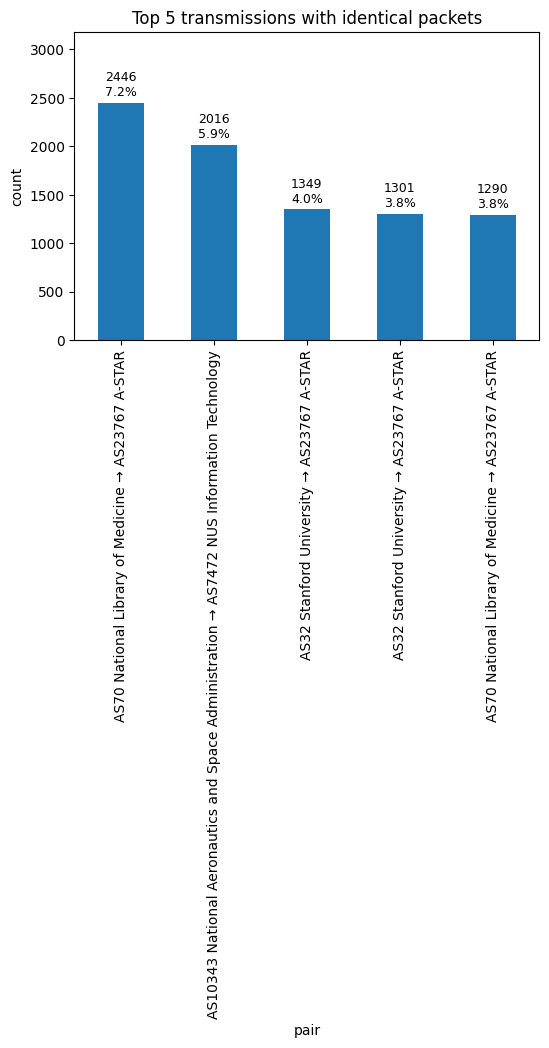

In [24]:
total_entries = all_aggregate_df["count"].sum()
all_aggregate_df = all_aggregate_df.head()


all_aggregate_df["pair"] = get_ip_details(all_aggregate_df["src_ip"], get_organisation=True) + " → " + get_ip_details(all_aggregate_df["dst_ip"], get_organisation=True) # type: ignore
draw_1_var_bar_chart("pair", all_aggregate_df, count_col="count", aggregated=True, title = "Top 5 transmissions with identical packets", rot=90, total_entries = total_entries)

Aggregating by flow


,flow,count,proportion
0,FLOW,176017,0.993145
1,CNTR,1215,0.006855


Aggregating by agent_ip


,agent_ip,count,proportion
0,203.30.38.251,177232,1.0


Aggregating by src_port_data_link_router


...

,packet_size,count,proportion
0,1522,25939,0.146356
1,1396,23317,0.131562
2,74,19238,0.108547
3,1438,16937,0.095564
4,62,13919,0.078535
...,...,...,...
1824,34153602,1,0.000006
1825,377,1,0.000006
1826,22483,1,0.000006
1827,45877460,1,0.000006


Aggregating by ip_size


,ip_size,count,proportion
0,1420,30412,0.171594
1,1500,29183,0.164660
2,1378,23632,0.133339
3,52,20858,0.117688
4,40,17767,0.100247
...,...,...,...
1416,787,1,0.000006
1417,939,1,0.000006
1418,731,1,0.000006
1419,746,1,0.000006


Aggregating by sampling_rate


,sampling_rate,count,proportion
0,2048,176017,0.993145
1,0,1215,0.006855


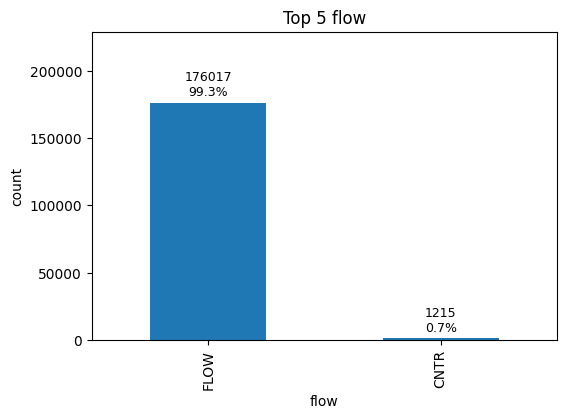

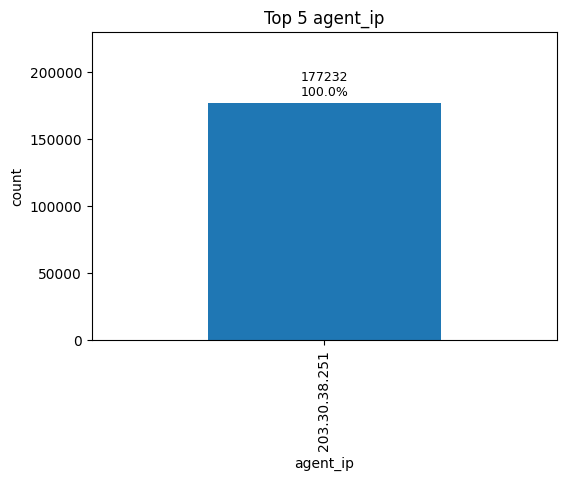

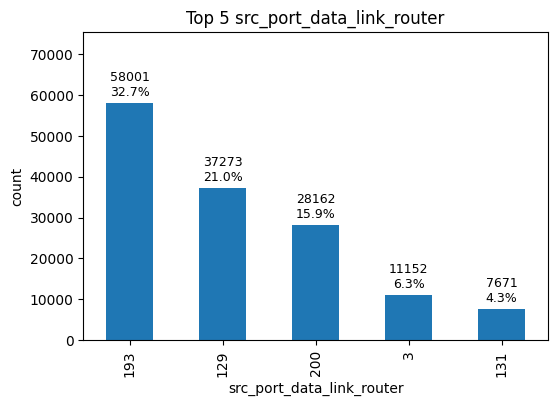

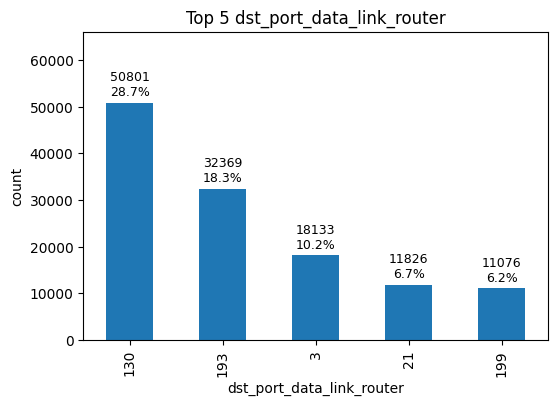

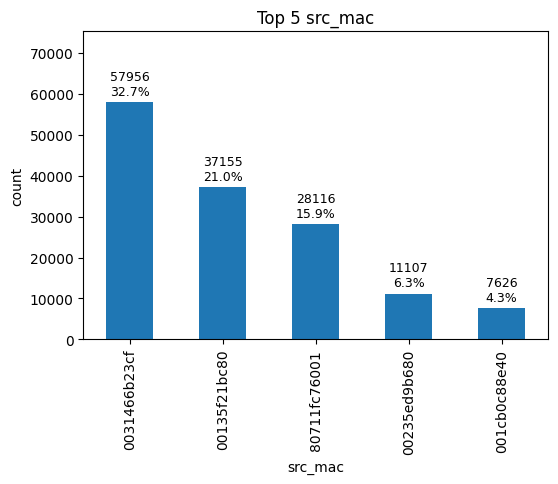

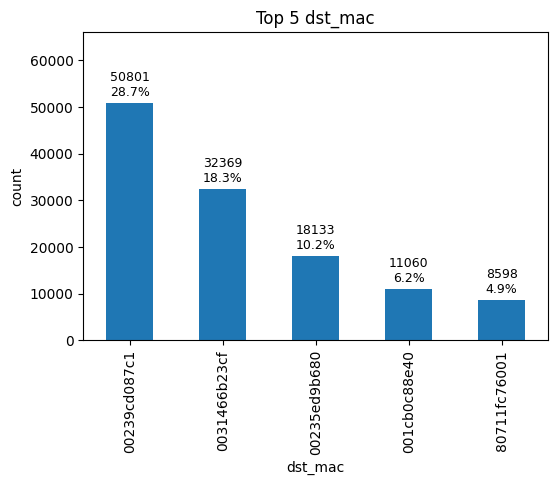

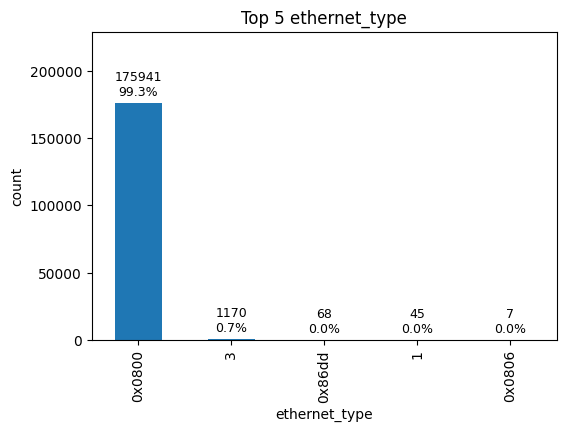

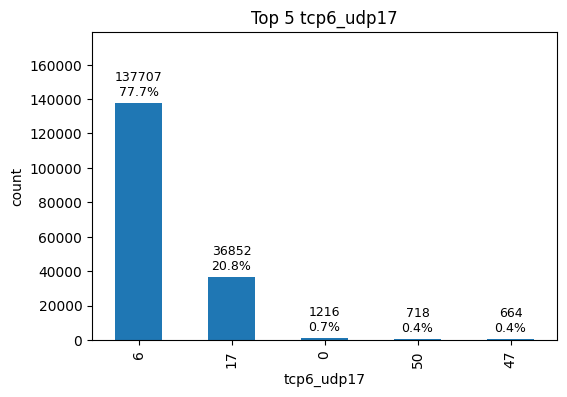

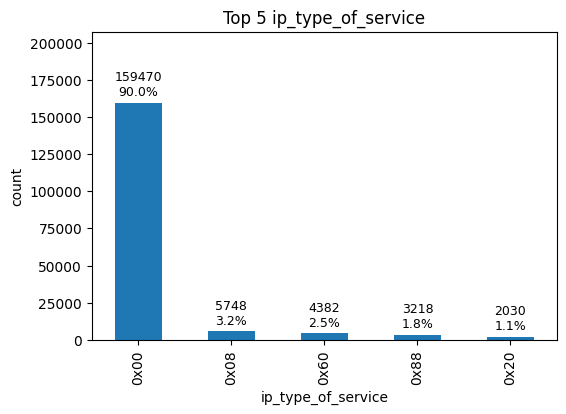

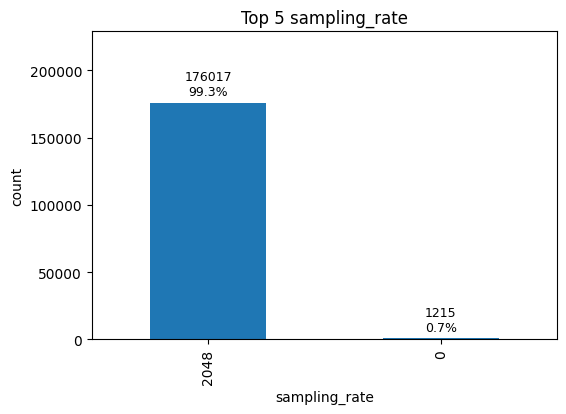

In [25]:
# patterns among every variable standalone
for col_name in col_names:
    _ = aggregate([col_name], df_data_2)

    #if less than 100 distinct values in column
    if _.shape[0] < 100:
        draw_1_var_bar_chart(col_name, _, rot = 90, aggregated=True, count_col="count")

Comments:

All aggregate: Looks like national library and Stanford have 2 different packets formats?

Flow: 1215 CNTR flow

Agent IP: everyone passes through cisco

src_port_data_link_router: 33% of data from the same port number. Not sure if can surmise anything though since it depends on the mac

dst_port_data_link_router: 29% of data goes to the same port number. Not sure if can surmise anything though since it depends on the mac

src_mac: first few places has a much higher proportion than src_ip. Could be interesting

dst_mac: same as src_mac

ethernet type: almost everyone using IPv4, very very few packets tagged as IPv6, surprisingly few ARP (0806), 0000 invalid/padding/malformed, 1 and 3 is probably corrupted

dst_vlan, src_vlan: alternative way to consider traffic:
e.g. destination:
VLAN 920  ➝ ~39.6% of traffic  
VLAN 11   ➝ ~21.0%  
VLAN 280  ➝ ~10.9%  
VLAN 691  ➝ ~7.2%  
VLAN 4095 ➝ ~5.3%
** VLAN 4096 is a reserved VLAN, could be misconfiguration or virtualized environment
** Lowkey VLAN 920 pretty important with almost 40 percent of traffic

src_ip, dst_ip: done earlier
tcp_udp: done earlier

ip_type_of_service: 
done earlier

src_port_transport_level:
done earlier

tcp_flags: 
0x10 (84%)→ ACK: Established traffic
0x00 (7%) → No flags set (Keepalive packets, Incomplete/malformed packets, Idle or control traffic, 
Some network scans)
0x18 (6.8%) → PSH + ACK: send data ack earlier data
0x11 (0.49%) → FIN + ACK: close connection
0x02 (0.43%) → SYN: start TCP connection

Packet size: 
Only 15% are around MTU sized packets = 1500 + headers
Alternate MTU values = 1396, 1438 due to Tunneling or VPN encapsulation/segmented traffic
Small packets(62-74): TCP acks/syn/fin/rst

ip size:
only around 30 to 40 % are standard sizes (1420, 1500, 1378), another 20% due to tcp control packets

sampling rate:
0 mean invalid/missing sampling config 